# Exercise 6.03 — Using a Scatter Plot to Visualize Correlation between Various Animals

**Student:** LU MENGJIE (MC643920)  
**Purpose:** Compare animal body mass and maximum longevity, separating the four classes and using logarithmic scales.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
from pathlib import Path

def locate_datasets():
    here = Path.cwd().resolve()
    for folder in (here, *here.parents):
        candidate = folder / "Datasets"
        if candidate.is_dir():
            return candidate
    raise FileNotFoundError("Could not find the project Datasets folder.")

DATASETS = locate_datasets()
print("Datasets:", DATASETS)

Datasets: C:\Users\22392\Desktop\cisc7204_sugex06_mc643920\Submission\cisc7204_sugex06_MC643920\Datasets


In [2]:
animals = pd.read_csv(DATASETS / 'anage_data.csv', index_col=0)
columns = ['Class', 'Maximum longevity (yrs)', 'Body mass (g)']
animals = animals[columns].copy()
animals = animals.replace([np.inf, -np.inf], np.nan).dropna(subset=columns[1:])
animals = animals[(animals['Maximum longevity (yrs)'] > 0) & (animals['Body mass (g)'] > 0)]
animals['Class'].value_counts()

Class
Mammalia    349
Aves        167
Amphibia     16
Reptilia     14
Name: count, dtype: int64

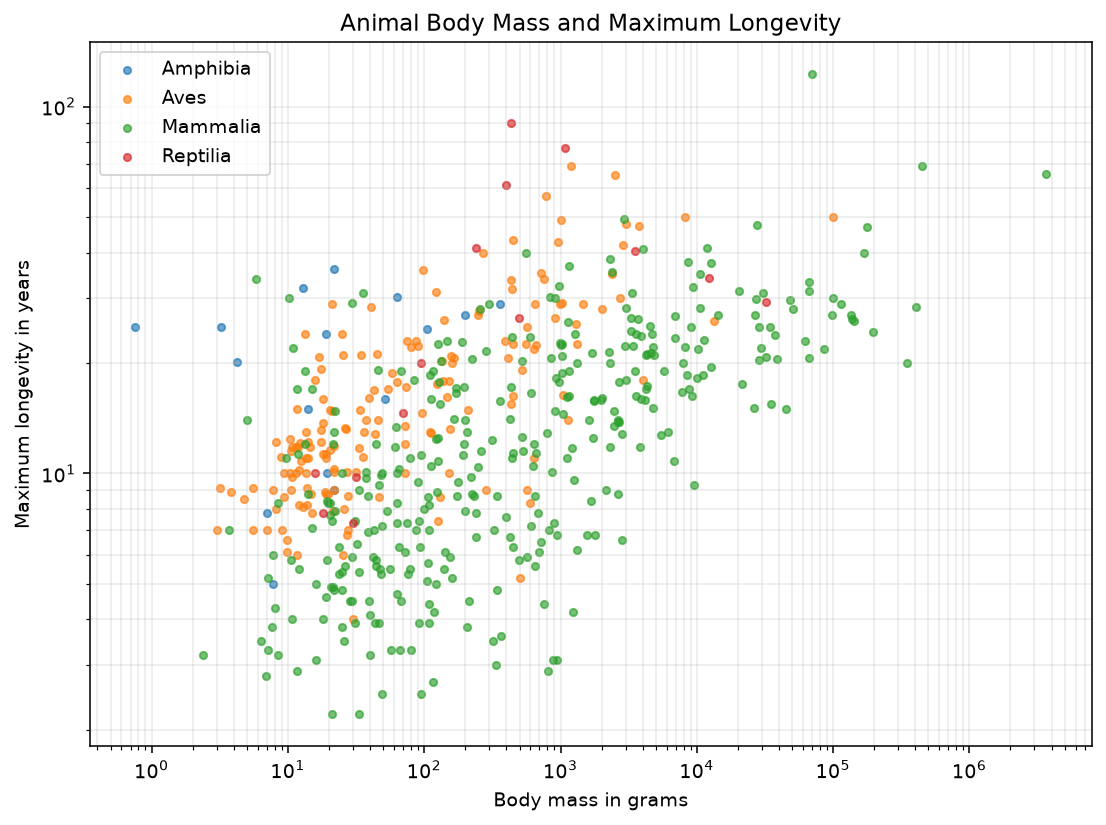

In [3]:
class_order = ['Amphibia', 'Aves', 'Mammalia', 'Reptilia']
fig, ax = plt.subplots(figsize=(8, 6), dpi=140)
for animal_class in class_order:
    group = animals.loc[animals['Class'] == animal_class]
    ax.scatter(group['Body mass (g)'], group['Maximum longevity (yrs)'],
               s=14, alpha=0.65, label=animal_class)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Body mass in grams')
ax.set_ylabel('Maximum longevity in years')
ax.set_title('Animal Body Mass and Maximum Longevity')
ax.legend()
ax.grid(True, which='both', alpha=0.25)
fig.tight_layout()
plt.show()